# AI Model Experiment & Evaluation
**Starter Notebook**

Notebook ini adalah kerangka awal untuk membandingkan dua pendekatan AI dalam menyelesaikan task sentiment analysis ulasan pelanggan:
1. Model klasik Machine Learning (Scikit-learn)
2. LLM API (Gemini)

Isi tiap section sesuai instruksi di Assignment Brief. Jangan ubah struktur section, tapi silakan tambah cell baru di dalam tiap section jika diperlukan.

> 🔧 **Catatan Penyesuaian Dataset**
>
> Notebook ini menggunakan dataset `customer_reviews_sentiment.csv` dengan kolom `review_text` dan `sentiment` (nilai: `positif`/`negatif`).
>
> Apabila dataset final berbeda dari yang digunakan saat ini, sesuaikan bagian berikut:
> - Nama file pada `pd.read_csv(...)` di Section 2
> - Nama kolom teks dan label pada Section 3 (saat ini: `review_text`, `sentiment`)
> - Label yang diminta pada prompt LLM di Section 5.2 (saat ini: `positif`/`negatif`)
> - Studi Kasus pada Assignment Brief, apabila domain data berbeda dari e-commerce

## 1. Problem Statement

Ulasan pelanggan dapat memberikan gambaran tentang pengalaman mereka terhadap produk dan layanan.  sentimen ulasan pelanggan diklasifikasikan menjadi positif atau negatif menggunakan TF-IDF dan Decision Tree dari scikit-learn. Hasil model klasik tersebut akan dibandingkan dengan prediksi Gemini API pada test set yang sama. Perbandingan dilakukan menggunakan Accuracy, Precision, Recall, dan F1-Score.

## 2. Import Library & Load Dataset

In [9]:
# 🔧 Sesuaikan nama file jika dataset final berbeda
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from google import genai  # sesuaikan dengan library Gemini API yang digunakan
from google.genai import types
import os

df = pd.read_csv('../data/customer_reviews_sentiment.csv - customer_reviews_sentiment.csv')
df.head()

,review_id,product_name,review_text,sentiment
0,1,Kemeja Flanel,Pelayanan lambat dan tidak responsif saat diko...,negatif
1,2,Case HP,"Puas banget belanja disini, proses cepat dan b...",positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai...",positif
3,4,Case HP,Warna produk berbeda jauh dari foto di listing.,negatif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai...",positif


## 3. Menyiapkan Train/Test Split

Pastikan test set yang sama digunakan untuk kedua pendekatan agar perbandingan adil.

In [10]:
# 🔧 Sesuaikan nama kolom jika dataset final menggunakan nama kolom berbeda
X = df['review_text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Train size:', len(X_train))
print('Test size:', len(X_test))

Train size: 160
Test size: 40


## 4. Pendekatan 1 — Model Klasik (Scikit-learn)

### 4.1 Preprocessing & Feature Extraction

In [11]:
vectorizer = TfidfVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

### 4.2 Training Model

In [12]:
# Decision Tree sesuai materi Pertemuan 1
clf = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=5,
    random_state=42
)
clf.fit(X_train_vec, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

### 4.3 Prediksi pada Test Set

In [13]:
y_pred_classic = clf.predict(X_test_vec)

## 5. Pendekatan 2 — LLM API (Gemini)

### 5.1 Setup API

In [17]:
# Simpan API key di environment variable, JANGAN hardcode langsung di notebook
client = genai.Client(api_key=os.environ.get('GEMINI_API_KEY'))

### 5.2 Merancang Prompt

Prompt meminta Gemini mengelompokkan ulasan ke dalam sentimen `positif` atau `negatif` dan membatasi jawaban hanya pada salah satu label. Pendekatan ini termasuk **zero-shot** karena model tidak diberi contoh ulasan beserta labelnya. Instruksi dibuat singkat dan jelas agar hasil prediksi lebih mudah dibandingkan dengan label pada dataset.

In [23]:
# 🔧 Sesuaikan label pada prompt jika dataset final menggunakan label berbeda
import time

def classify_sentiment_llm(review_text):
    prompt = f'''Klasifikasikan sentimen ulasan berikut sebagai "positif" atau "negatif".
Jawab hanya dengan satu kata: positif atau negatif.

Ulasan: "{review_text}"
Sentimen:'''
    for attempt in range(3):
        try:
            response = client.models.generate_content(
                model='gemini-3.8-flash',  # sesuaikan versi model
                contents=prompt,
                config=types.GenerateContentConfig(temperature=0.2)
            )
            return response.text.strip().lower()
        except Exception as error:
            status_code = getattr(error, 'code', None) or getattr(error, 'status_code', None)
            if status_code not in (429, 503) or attempt == 2:
                raise
            time.sleep(10 * (attempt + 1))

### 5.3 Menjalankan Prediksi pada Test Set

Catatan: lakukan normalisasi terhadap output LLM sebelum dibandingkan dengan label asli (misal: lowercase, strip whitespace).

In [24]:
y_pred_llm = []
for review in X_test:
    pred = classify_sentiment_llm(review)
    y_pred_llm.append(pred)

# TODO: normalisasi y_pred_llm agar konsisten dengan label 'positif'/'negatif'

ClientError: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 5, model: gemini-3.8-flash\nPlease retry in 13.14904188s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerMinutePerProjectPerModel-FreeTier', 'quotaDimensions': {'model': 'gemini-3.8-flash', 'location': 'global'}

## 6. Evaluasi dan Perbandingan

### 6.1 Evaluasi Model Klasik

In [9]:
print('=== Model Klasik (Scikit-learn) ===')
print('Accuracy:', accuracy_score(y_test, y_pred_classic))
print(classification_report(y_test, y_pred_classic))
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred_classic))

=== Model Klasik (Scikit-learn) ===
Accuracy: 1.0
              precision    recall  f1-score   support

     negatif       1.00      1.00      1.00        18
     positif       1.00      1.00      1.00        22

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40

Confusion Matrix:
 [[18  0]
 [ 0 22]]


### 6.2 Evaluasi LLM API

In [10]:
print('=== LLM API (Gemini) ===')
print('Accuracy:', accuracy_score(y_test, y_pred_llm))
print(classification_report(y_test, y_pred_llm))
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred_llm))

=== LLM API (Gemini) ===


ValueError: Found input variables with inconsistent numbers of samples: [40, 6]

### 6.3 Tabel Perbandingan Ringkasan

_Susun tabel ringkasan (bisa markdown table atau DataFrame) yang membandingkan Accuracy, Precision, Recall, F1-Score kedua pendekatan._

Evaluation on Data Training:
Accuracy: 0.9000

Classification Report:
              precision    recall  f1-score   support

     negatif       0.82      1.00      0.90        72
     positif       1.00      0.82      0.90        88

    accuracy                           0.90       160
   macro avg       0.91      0.91      0.90       160
weighted avg       0.92      0.90      0.90       160

Evaluation on Data Testing:
Accuracy: 0.8250

Classification Report:
              precision    recall  f1-score   support

     negatif       0.72      1.00      0.84        18
     positif       1.00      0.68      0.81        22

    accuracy                           0.82        40
   macro avg       0.86      0.84      0.82        40
weighted avg       0.87      0.82      0.82        40



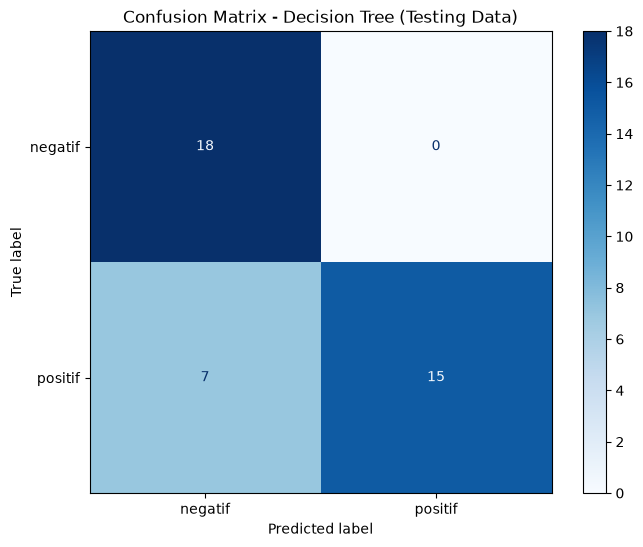

In [15]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Evaluasi model Decision Tree sesuai format Pertemuan 1
y_pred_training = clf.predict(X_train_vec)
y_pred_test = clf.predict(X_test_vec)

print('Evaluation on Data Training:')
print(f'Accuracy: {accuracy_score(y_train, y_pred_training):.4f}')
print('\nClassification Report:')
print(classification_report(y_train, y_pred_training))

print('Evaluation on Data Testing:')
print(f'Accuracy: {accuracy_score(y_test, y_pred_test):.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_test))

cm = confusion_matrix(y_test, y_pred_test, labels=clf.classes_)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=clf.classes_
)
fig, ax = plt.subplots(figsize=(8, 6))
display.plot(cmap='Blues', ax=ax)
plt.title('Confusion Matrix - Decision Tree (Testing Data)')
plt.show()

## 7. Analisis Trade-off dan Limitation

Dari hasil pengujian, model Decision Tree mendapatkan accuracy **0.8250** pada data testing. Hasil ini cukup baik, tetapi masih ada beberapa data yang salah diklasifikasikan. Dari confusion matrix terlihat bahwa 9 data negatif diprediksi sebagai positif dan 5 data positif diprediksi sebagai negatif.

Kelebihan metode ini adalah prosesnya cepat dan bisa dijalankan langsung di komputer tanpa API. TF-IDF juga cukup sederhana untuk mengubah teks menjadi angka. Kekurangannya, model hanya belajar dari kata-kata yang ada pada data training, sehingga belum tentu memahami konteks kalimat, sarkasme, typo, atau kata baru.

Model juga mendapatkan accuracy training yang lebih tinggi daripada testing. Ini menunjukkan bahwa model lebih cocok dengan data training. Karena dataset yang digunakan tidak terlalu besar, hasilnya masih perlu diuji lagi dengan data yang lebih banyak.

## 8. Rekomendasi Technical Approach

Untuk percobaan ini, saya memilih  Decision Tree karena metode ini sesuai dengan materi yang sudah dipelajari dan bisa dijalankan tanpa koneksi API.

Model ini cukup cepat untuk digunakan pada dataset kecil seperti data ulasan pelanggan. Hasil testing mendapatkan accuracy 0.8250, dengan precision 0.8740, recall 0.8250, dan F1-Score 0.8227.

Menurut saya, metode ini masih bisa digunakan sebagai model awal karena sederhana, cepat, dan tidak membutuhkan biaya API.

Gemini API bisa digunakan sebagai pembanding, tetapi memiliki keterbatasan kuota request. Selain itu, biaya penggunaannya bisa menjadi lebih mahal jika jumlah ulasan yang diproses semakin banyak.